In [1]:
from google.colab import files
uploaded = files.upload()

Saving CodeAlpha_Web_Scraping.csv to CodeAlpha_Web_Scraping.csv


In [2]:
import pandas as pd

df = pd.read_csv("CodeAlpha_Web_Scraping.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (1000, 4)


,Title,Price,Rating,Availability
0,A Light in the Attic,£51.77,Three,In stock
1,Tipping the Velvet,£53.74,One,In stock
2,Soumission,£50.10,One,In stock
3,Sharp Objects,£47.82,Four,In stock
4,Sapiens: A Brief History of Humankind,£54.23,Five,In stock


In [3]:
# Check column names
print("Column Names:")
print(df.columns.tolist())

# Check data types
print("\nData Types:")
print(df.dtypes)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:")
print(df.duplicated().sum())

# Get a summary of the dataset
print("\nDataset Information:")
df.info()

Column Names:
['Title', 'Price', 'Rating', 'Availability']

Data Types:
Title           object
Price           object
Rating          object
Availability    object
dtype: object

Missing Values:
Title           0
Price           0
Rating          0
Availability    0
dtype: int64

Duplicate Rows:
0

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Title         1000 non-null   object
 1   Price         1000 non-null   object
 2   Rating        1000 non-null   object
 3   Availability  1000 non-null   object
dtypes: object(4)
memory usage: 31.4+ KB


In [4]:
# Remove the pound symbol and convert prices to numbers
df["Price"] = df["Price"].str.replace("£", "", regex=False).astype(float)

print("Price conversion completed!")
print(df["Price"].head())

Price conversion completed!
0    51.77
1    53.74
2    50.10
3    47.82
4    54.23
Name: Price, dtype: float64


In [5]:
# Statistical analysis of book prices

print("Price Analysis")
print("--------------------")

print("Average price:", round(df["Price"].mean(), 2))
print("Highest price:", df["Price"].max())
print("Lowest price:", df["Price"].min())
print("Median price:", df["Price"].median())

print("\nComplete price statistics:")
print(df["Price"].describe())

Price Analysis
--------------------
Average price: 35.07
Highest price: 59.99
Lowest price: 10.0
Median price: 35.980000000000004

Complete price statistics:
count    1000.00000
mean       35.07035
std        14.44669
min        10.00000
25%        22.10750
50%        35.98000
75%        47.45750
max        59.99000
Name: Price, dtype: float64


In [6]:
print("Book Rating Distribution")
print("------------------------")

print(df["Rating"].value_counts())

print("\nRating percentages:")
print((df["Rating"].value_counts(normalize=True) * 100).round(2))

Book Rating Distribution
------------------------
Rating
One      226
Three    203
Five     196
Two      196
Four     179
Name: count, dtype: int64

Rating percentages:
Rating
One      22.6
Three    20.3
Five     19.6
Two      19.6
Four     17.9
Name: proportion, dtype: float64


In [7]:
print("Book Availability")
print("-----------------")

print(df["Availability"].value_counts())

Book Availability
-----------------
Availability
In stock    1000
Name: count, dtype: int64


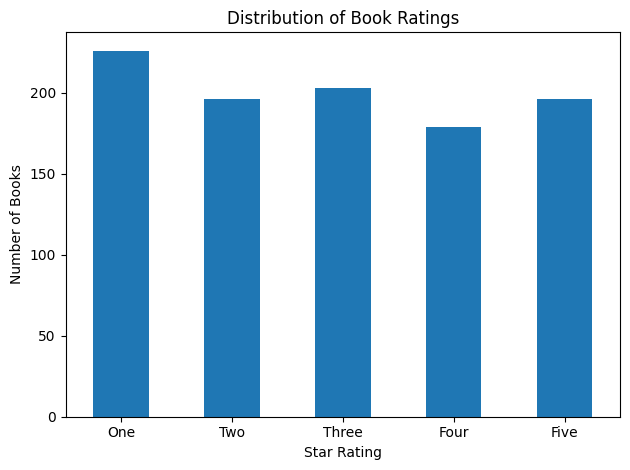

In [8]:
import matplotlib.pyplot as plt

rating_counts = df["Rating"].value_counts().reindex(
    ["One", "Two", "Three", "Four", "Five"]
)

rating_counts.plot(kind="bar")

plt.title("Distribution of Book Ratings")
plt.xlabel("Star Rating")
plt.ylabel("Number of Books")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

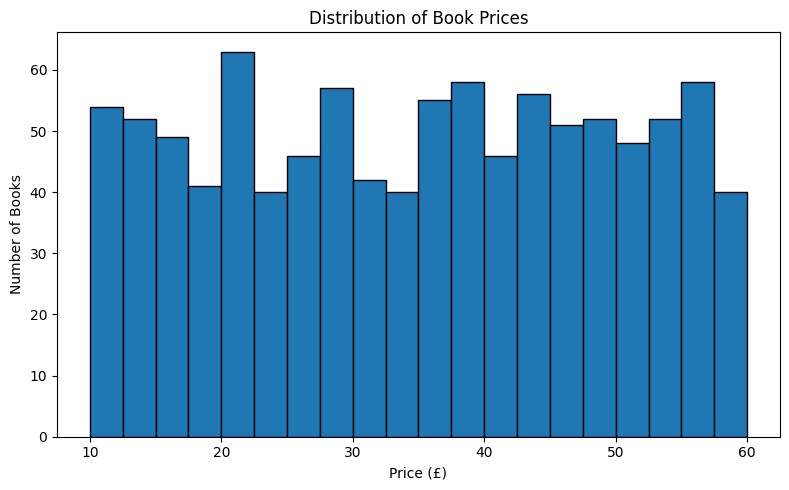

In [9]:
plt.figure(figsize=(8, 5))

plt.hist(df["Price"], bins=20, edgecolor="black")

plt.title("Distribution of Book Prices")
plt.xlabel("Price (£)")
plt.ylabel("Number of Books")
plt.tight_layout()
plt.show()

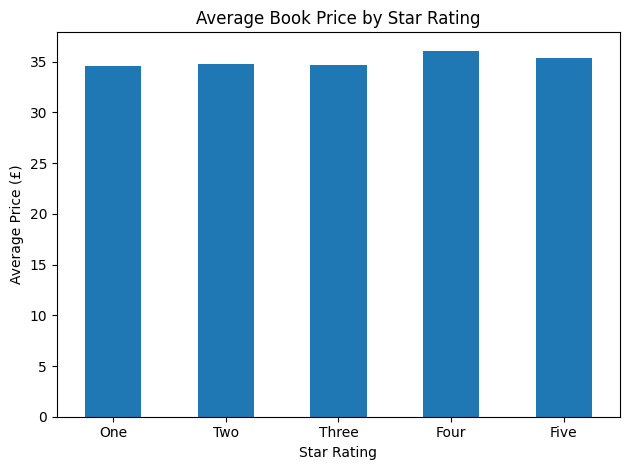

In [10]:
average_price = df.groupby("Rating")["Price"].mean().reindex(
    ["One", "Two", "Three", "Four", "Five"]
)

average_price.plot(kind="bar")

plt.title("Average Book Price by Star Rating")
plt.xlabel("Star Rating")
plt.ylabel("Average Price (£)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
print("FINAL EDA SUMMARY")
print("==================")

print("Total books analyzed:", len(df))
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Average book price: £", round(df["Price"].mean(), 2))
print("Highest book price: £", df["Price"].max())
print("Lowest book price: £", df["Price"].min())

print("\nMost common rating:")
print(df["Rating"].value_counts().idxmax())

print("\nAvailability:")
print(df["Availability"].value_counts())

FINAL EDA SUMMARY
Total books analyzed: 1000
Missing values: 0
Duplicate rows: 0
Average book price: £ 35.07
Highest book price: £ 59.99
Lowest book price: £ 10.0

Most common rating:
One

Availability:
Availability
In stock    1000
Name: count, dtype: int64


## Key Findings

1. The dataset contains 1,000 book records and four columns.
2. No missing values were found in the dataset.
3. Book prices were converted into numeric values for statistical analysis.
4. One-star ratings were the most common, representing 22.6% of the books.
5. All 1,000 books were listed as in stock.
6. Bar charts and a histogram were used to explore rating and price distributions.

## Conclusion

Exploratory Data Analysis helped summarize book prices, ratings, and availability. The charts and statistical summaries made it easier to identify patterns in the dataset. This project demonstrates basic data analysis using Python, Pandas, and Matplotlib.